## BRCA prediction with the UNI2 pretrained model

Score Xenium BRCA rep1 and rep2 with the pan-cancer UNI2 checkpoint chosen from the A0–A3 ablation:

`data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate/cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt`

A3 is adjacent loss plus spatial k=8 mean and a learned gate. The BRCA-only UNI training notebook stays in `BRCA_train_validate_cv_UNIlabel_all.ipynb`.

- Embeddings are the UNI2 class token, `Cases/{rep}/project_all_UNI2/ImgEmbeddings_all/sc_pth_14_14` (1536-d). `h5ad.X` is still UNI.
- Spatial context stays on. The checkpoint stores k=8 mean and the gate.
- `--deployment` applies this one file to both replicates. The scores are not cross-section OOF.
- `best_mlp_gpu.pt` is fold 0. **rep1 is held out** of this file. **rep2 is fold 1** and was in its training sections. The number for this weight on BRCA is rep1.
- Labels are the pan-cancer ontology. ROC tables are GT-matched cells.
- All-nuclei StarDist maps use `ImgEmbeddings_all_stardist/sc_pth_14_14`. Those tokens are not on disk yet. Extract them, then re-run the predict cell; a finished matched-cell section still writes the missing all-nuclei h5ad.

Env: `conda activate SeededNTM`. Run the cells in order. `RUN_A3_PRED = True` with `--skip-existing` leaves a finished section in place. Set `SKIP_A3_FIGURES = False` to draw the matched-cell panel; a section whose panel PNG is missing is recomputed.


In [1]:
import os
import warnings

warnings.filterwarnings("ignore")
os.environ.setdefault("NCRT_CUDA_DEVICE", "0")

import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
for _d in (REPO / "code/Hist2Pheno_pkg", REPO / "code/PanCancer"):
    if str(_d) not in sys.path:
        sys.path.insert(0, str(_d))

from runtime_env import configure_notebook_runtime
_rt_env = configure_notebook_runtime()
print(f"CUDA_VISIBLE_DEVICES={os.environ.get('CUDA_VISIBLE_DEVICES')} (physical GPU {_rt_env['physical_gpu']})")


CUDA_VISIBLE_DEVICES=0 (physical GPU 0)
CUDA_VISIBLE_DEVICES=0 (physical GPU 0)


In [2]:
import subprocess

A3_CKPT = (
    REPO
    / "data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate"
    / "cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt"
)
A3_PRED = REPO / "data/PanCancer/pred_uni2_A3_bestmlp"
A3_ROC = A3_PRED / "stardist_roc"
RUN_A3_PRED = True
SKIP_A3_FIGURES = True

if not A3_CKPT.is_file():
    raise FileNotFoundError(A3_CKPT)

cmd = [
    sys.executable,
    "-u",
    str(REPO / "code/PanCancer/PanCancer_predict_visualize.py"),
    "--cuda-device",
    os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0],
    "--embedder",
    "uni2",
    "--deployment",
    "--spatial-k",
    "8",
    "--datasets",
    "BRCA",
    # "--skip-existing",    # new generate .h5ad
    "--checkpoint",
    str(A3_CKPT),
    "--pred-root",
    str(A3_PRED),
    "--data-root",
    str(REPO / "data/PanCancer"),
]
if SKIP_A3_FIGURES:
    cmd.append("--skip-figures")
print(" ".join(cmd))
if RUN_A3_PRED:
    subprocess.run(cmd, check=True, cwd=str(REPO))
else:
    print("RUN_A3_PRED=False; reading ROC tables under", A3_ROC)


/nobackup2/users/lingyu/conda_envs/SeededNTM/bin/python -u /home/lingyu/ssd2/Python/Hist2Pheno/code/PanCancer/PanCancer_predict_visualize.py --cuda-device 0 --embedder uni2 --deployment --spatial-k 8 --datasets BRCA --checkpoint /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate/cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt --pred-root /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp --data-root /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer --skip-figures
Pan-cancer predict / visualize
  ckpt:   /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate/cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt
  out:    /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp
  device: cuda:0  spatial=True  embedder=uni2
Loading best model for StarDist prediction...
  Checkpoint file: /nobackup2/users/lingyu/Python/Hist2Pheno/d

Loading .pth files (workers=16): 100%|██████████| 157183/157183 [02:27<00:00, 1065.20it/s]


  Successfully loaded 157183 embeddings
  Embedding dimension: (1536,)

  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 157,183 points
  KDTree matched 157,183 / 157,183 cells (100.00%).
  UNI2 aligned 157,183/157,183 rows, dim=1536
  UNI2 match rep1 ← /nobackup2/users/lingyu/Python/Hist2Pheno/data/Xemium/BRCA/Cases/rep1/project_all_UNI2/ImgEmbeddings_all_stardist/sc_pth_14_14
Loading HIPT embeddings (full scan: 252,160 .pth files, cap=400,000; skipping selective path probe).
  Loading embeddings...


Loading .pth files (workers=16): 100%|██████████| 252160/252160 [03:50<00:00, 1093.90it/s]


  Successfully loaded 252160 embeddings
  Embedding dimension: (1536,)

  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 252,160 points
  KDTree matched 252,158 / 252,158 cells (100.00%).
  UNI2 aligned 252,158/252,158 rows, dim=1536
  BRCA::rep1: n=157,016  L2 AUROC=0.855  stardist_all=252,158
  UNI2 match rep2 ← /nobackup2/users/lingyu/Python/Hist2Pheno/data/Xemium/BRCA/Cases/rep2/project_all_UNI2/ImgEmbeddings_all/sc_pth_14_14
Loading HIPT embeddings (full scan: 107,318 .pth files, cap=400,000; skipping selective path probe).
  Loading embeddings...


Loading .pth files (workers=16): 100%|██████████| 107318/107318 [01:41<00:00, 1057.09it/s]


  Successfully loaded 107318 embeddings
  Embedding dimension: (1536,)

  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 107,318 points
  KDTree matched 107,312 / 107,312 cells (100.00%).
  UNI2 aligned 107,312/107,312 rows, dim=1536
  UNI2 match rep2 ← /nobackup2/users/lingyu/Python/Hist2Pheno/data/Xemium/BRCA/Cases/rep2/project_all_UNI2/ImgEmbeddings_all_stardist/sc_pth_14_14
Loading HIPT embeddings (full scan: 245,326 .pth files, cap=400,000; skipping selective path probe).
  Loading embeddings...


Loading .pth files (workers=16): 100%|██████████| 245326/245326 [04:00<00:00, 1021.26it/s]


  Successfully loaded 245326 embeddings
  Embedding dimension: (1536,)

  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 245,326 points
  KDTree matched 245,246 / 245,246 cells (100.00%).
  UNI2 aligned 245,246/245,246 rows, dim=1536
  BRCA::rep2: n=107,180  L2 AUROC=0.904  stardist_all=245,246

Wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/metrics_per_section.csv  n=896
  BRCA              n=   2  mean L2 AUROC=0.879
  CRC               n=   3  mean L2 AUROC=0.768
  GBM               n=   2  mean L2 AUROC=0.648
  GIST              n= 550  mean L2 AUROC=0.666
  HCC               n=  36  mean L2 AUROC=0.760
  Lung              n=  25  mean L2 AUROC=0.717
  PDAC              n= 278  mean L2 AUROC=0.767
Done; failures=0


Per-replicate macro AUROC on GT-matched cells. rep1 is the held-out section for this checkpoint.


tier,L1,L12,L2
sample,,,
rep1,0.885590,0.864870,0.854702
rep2,0.928419,0.917416,0.903776


Linked 2/2 StarDist sample dirs under /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_roc
Linked 1/1 StarDist sample dirs under /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_heldout_rep1_roc

=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
  BRCA__rep2: 107,180 cells, 20 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/validation_external_stardist_matched_AUROC_all_samples_concat.csv (264,196 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/validation_external_stardist_matched_AUROC_all_samples_class_names.csv (20 classes)
Pooled: 264,196 cells from 2 samples; 20 global final_CT classes
  ROC colors: pancancer_l2 (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/

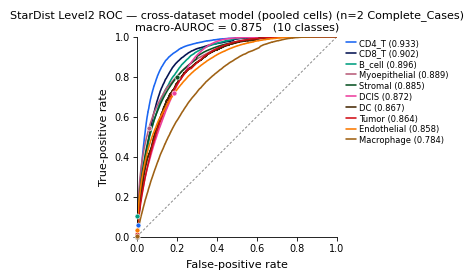

Pooled macro AUROC (L2): 0.8750

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
  BRCA__rep2: 107,180 cells, 8 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/validation_external_stardist_matched_AUROC_level12_all_samples_concat.csv (264,196 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/validation_external_stardist_matched_AUROC_level12_all_samples_class_names.csv (8 classes)
Pooled: 264,196 cells from 2 samples; 8 global final_sublineage classes
  ROC colors: pancancer_l12 (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/roc_stardist_l12_cross_dataset_all_Complete_Cases_pooled.pdf


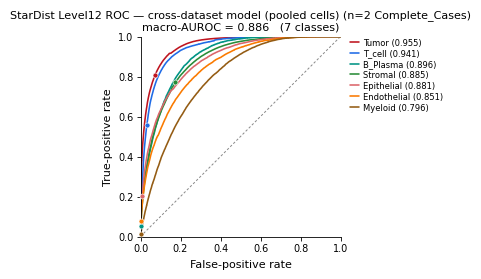

Pooled macro AUROC (L12): 0.8863

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
  BRCA__rep2: 107,180 cells, 5 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/validation_external_stardist_matched_AUROC_level1_all_samples_concat.csv (264,196 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/validation_external_stardist_matched_AUROC_level1_all_samples_class_names.csv (5 classes)
Pooled: 264,196 cells from 2 samples; 5 global final_lineage classes
  ROC colors: pancancer_l1 (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc/roc_stardist_l1_cross_dataset_all_Complete_Cases_pooled.pdf


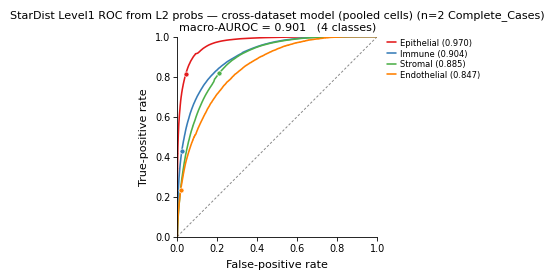

Pooled macro AUROC (L1): 0.9015
rep1+rep2. rep2 was in the training sections of this weight.
  pooled L2 macro AUROC = 0.8750
  pooled L12 macro AUROC = 0.8863
  pooled L1 macro AUROC = 0.9015

=== L2 | discovering validation_external_stardist_matched_AUROC.csv ===
  BRCA__rep1: 157,016 cells, 20 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/validation_external_stardist_matched_AUROC_all_samples_concat.csv (157,016 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/validation_external_stardist_matched_AUROC_all_samples_class_names.csv (20 classes)
Pooled: 157,016 cells from 1 samples; 20 global final_CT classes
  ROC colors: pancancer_l2 (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/roc_stardist_

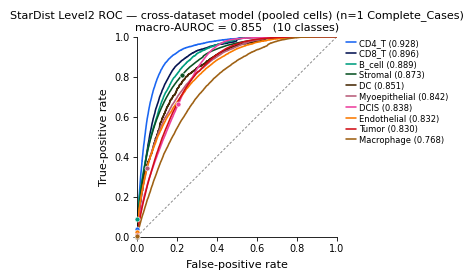

Pooled macro AUROC (L2): 0.8547

=== L12 | discovering validation_external_stardist_matched_AUROC_level12.csv ===
  BRCA__rep1: 157,016 cells, 8 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/validation_external_stardist_matched_AUROC_level12_all_samples_concat.csv (157,016 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/validation_external_stardist_matched_AUROC_level12_all_samples_class_names.csv (8 classes)
Pooled: 157,016 cells from 1 samples; 8 global final_sublineage classes
  ROC colors: pancancer_l12 (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/roc_stardist_l12_cross_dataset_all_Complete_Cases_pooled.pdf


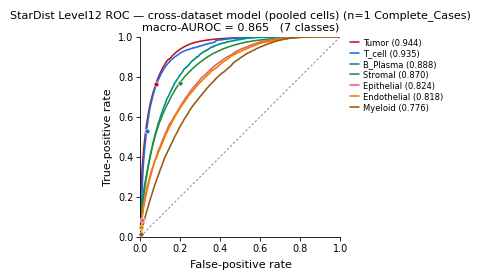

Pooled macro AUROC (L12): 0.8649

=== L1 | discovering validation_external_stardist_matched_AUROC_level1.csv ===
  BRCA__rep1: 157,016 cells, 5 local classes
Saved pooled AUROC concat: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/validation_external_stardist_matched_AUROC_level1_all_samples_concat.csv (157,016 rows)
Saved global class names: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/validation_external_stardist_matched_AUROC_level1_all_samples_class_names.csv (5 classes)
Pooled: 157,016 cells from 1 samples; 5 global final_lineage classes
  ROC colors: pancancer_l1 (aligned with dataset spatial palette).
  ✓ Saved ROC figure: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/brca_pooled_roc_heldout_rep1/roc_stardist_l1_cross_dataset_all_Complete_Cases_pooled.pdf


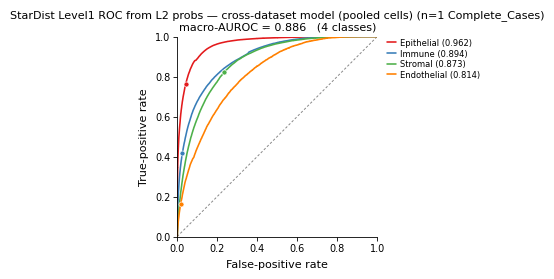

Pooled macro AUROC (L1): 0.8856
rep1 only. This is the held-out section for best_mlp.
  pooled L2 macro AUROC = 0.8547
  pooled L12 macro AUROC = 0.8649
  pooled L1 macro AUROC = 0.8856


In [3]:
import numpy as np
import pandas as pd
from uni_label_cv_helpers import (
    macro_auc_ovr,
    plot_pooled_stardist_tier_rocs,
    stardist_auroc_tier_spec,
    symlink_stardist_sample_dirs,
)

# rep1 is held out of best_mlp (fold 0). rep2 is fold 1 and was in its training sections.
SAMPLES = {"rep1": "BRCA__rep1", "rep2": "BRCA__rep2"}
TIERS = ("l2", "l12", "l1")


def section_macro(sample_dir: Path, tier: str):
    spec = stardist_auroc_tier_spec(tier)
    df = pd.read_csv(sample_dir / spec["csv_name"])
    prob_cols = [c for c in df.columns if c.startswith("prob_")]
    y = df["ground_truth_idx"].to_numpy()
    score = df[prob_cols].to_numpy(dtype=np.float64)
    return macro_auc_ovr(y, score, score.shape[1]), int(len(df))


rows = []
for name, dirname in SAMPLES.items():
    sample_dir = A3_ROC / dirname
    if not sample_dir.is_dir():
        raise FileNotFoundError(sample_dir)
    for tier in TIERS:
        auc, n = section_macro(sample_dir, tier)
        rows.append({"sample": name, "tier": tier.upper(), "n_cells": n, "macro_auroc": auc})

per_sample = pd.DataFrame(rows)
print("Per-replicate macro AUROC on GT-matched cells. rep1 is the held-out section for this checkpoint.")
display(per_sample.pivot(index="sample", columns="tier", values="macro_auroc"))

both = A3_PRED / "brca_roc"
held = A3_PRED / "brca_heldout_rep1_roc"
symlink_stardist_sample_dirs(A3_ROC, list(SAMPLES.values()), both)
symlink_stardist_sample_dirs(A3_ROC, ["BRCA__rep1"], held)


def pool(root, out, label):
    out.mkdir(parents=True, exist_ok=True)
    results = plot_pooled_stardist_tier_rocs(
        root,
        out,
        tiers=TIERS,
        layout="pooled_stardist",
        pan_organ="pancancer",
        figsize=(2.0, 2.0),
        show_barplot=False,
        save_per_class_csv=True,
        show=True,
    )
    print(label)
    for tier, rec in results.items():
        info = rec.get("roc_info") or {}
        print(f"  pooled {tier.upper()} macro AUROC = {info.get('macro_auc', float('nan')):.4f}")
    return results


results_brca = pool(
    both,
    A3_PRED / "brca_pooled_roc",
    "rep1+rep2. rep2 was in the training sections of this weight.",
)
results_rep1 = pool(
    held,
    A3_PRED / "brca_pooled_roc_heldout_rep1",
    "rep1 only. This is the held-out section for best_mlp.",
)


## All StarDist nuclei

This is the UNI2 counterpart of §5 in `BRCA_train_validate_cv_UNIlabel_all.ipynb`: every StarDist nucleus, no matched-cell AUROC. It uses the same A3 checkpoint. It does not retrain a BRCA-only model.

GT UNI2 tokens cannot stand in for StarDist centroids. The full StarDist tables are 252,179 (rep1) and 245,840 (rep2) nuclei.

The rep1 extract stopped at 8,683 `.pth` files (the map with n=8,681) and also wrote 252,160 patch PNGs. The rep2 extract finished (245,326 `.pth`), but the alignment cache was written while it was still running, so the h5ad only had 129,062 nuclei.

Run this yourself in a terminal. It removes the incomplete rep1 tokens, the patch PNGs, both short all-nuclei h5ads, and the two alignment caches. rep2's finished tokens stay. The extract then reruns rep1 and skips rep2. Do not start it while another `brca stardist` job is writing.

```bash
cd /home/lingyu/ssd2/Python/Hist2Pheno

rm -rf data/Xemium/BRCA/Cases/rep1/project_all_UNI2/ImgEmbeddings_all_stardist/sc_pth_14_14
rm -rf data/Xemium/BRCA/Cases/rep1/project_all_UNI2/ImgEmbeddings_all_stardist/sc_pth_14_14_image

rm -f data/PanCancer/uni2_aligned/8ed0657dc657b431d64feb7e1d0325b374c0673becf3f9676800934f30b37266.json \
      data/PanCancer/uni2_aligned/8ed0657dc657b431d64feb7e1d0325b374c0673becf3f9676800934f30b37266.npy \
      data/PanCancer/uni2_aligned/fb1792c107ec28ee6598d8197fe57ba5130d843ca76d980e4b424f34f31fb42b.json \
      data/PanCancer/uni2_aligned/fb1792c107ec28ee6598d8197fe57ba5130d843ca76d980e4b424f34f31fb42b.npy

rm -f data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep1/rep1_all_stardist_pred.h5ad \
      data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep1/rep1_stardist_pred_*.jpg \
      data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep2/rep2_all_stardist_pred.h5ad \
      data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep2/rep2_stardist_pred_*.jpg \
      data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/stardist_all_pred_overview.jpg

SAVE_PATCH_IMAGES=0 bash code/Hist2Pheno_pkg/run_uni2_patch14.sh brca stardist 0
```

After that extract finishes, re-run the predict cell above, then the plot cell. `--skip-existing` still refits a section whose all-nuclei h5ad was removed. The plot cell draws `{sample}_stardist_pred_{l2,l12,l1}.jpg` in the notebook and on disk.


Number of valid data points: 252158
Number of cell types: 19
  Saved predicted spatial plot: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep1/rep1_stardist_pred_l2.jpg
  saved rep1_stardist_pred_l2.jpg
Number of valid data points: 252158
Number of cell types: 7
  Saved predicted spatial plot: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep1/rep1_stardist_pred_l12.jpg
  saved rep1_stardist_pred_l12.jpg
Number of valid data points: 252158
Number of cell types: 5
  Saved predicted spatial plot: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep1/rep1_stardist_pred_l1.jpg
  saved rep1_stardist_pred_l1.jpg


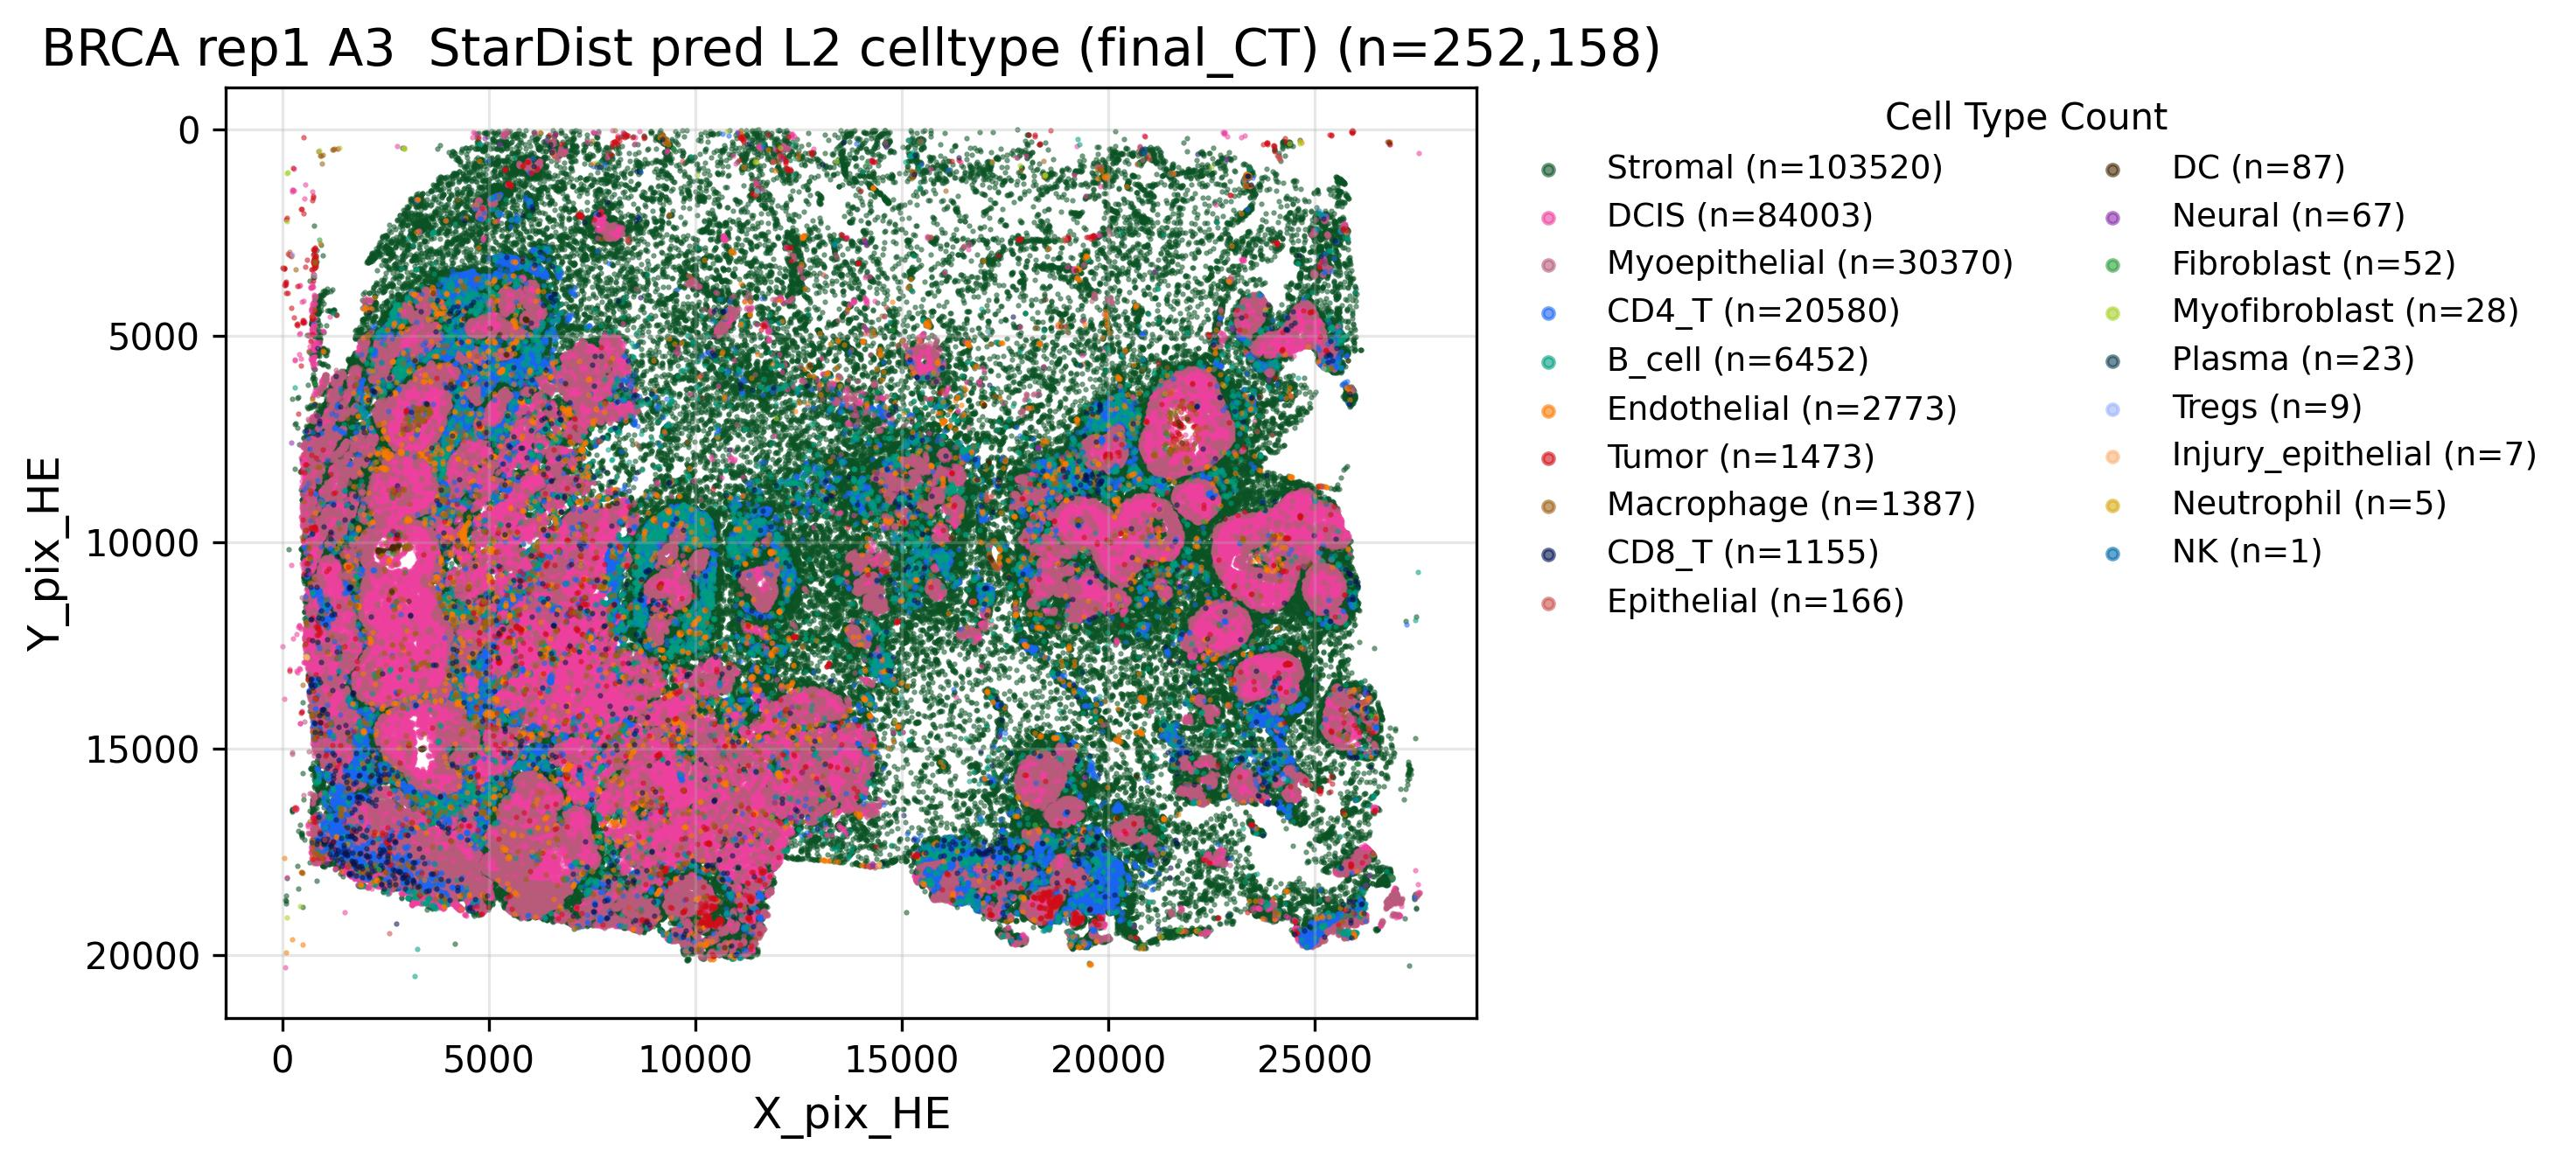

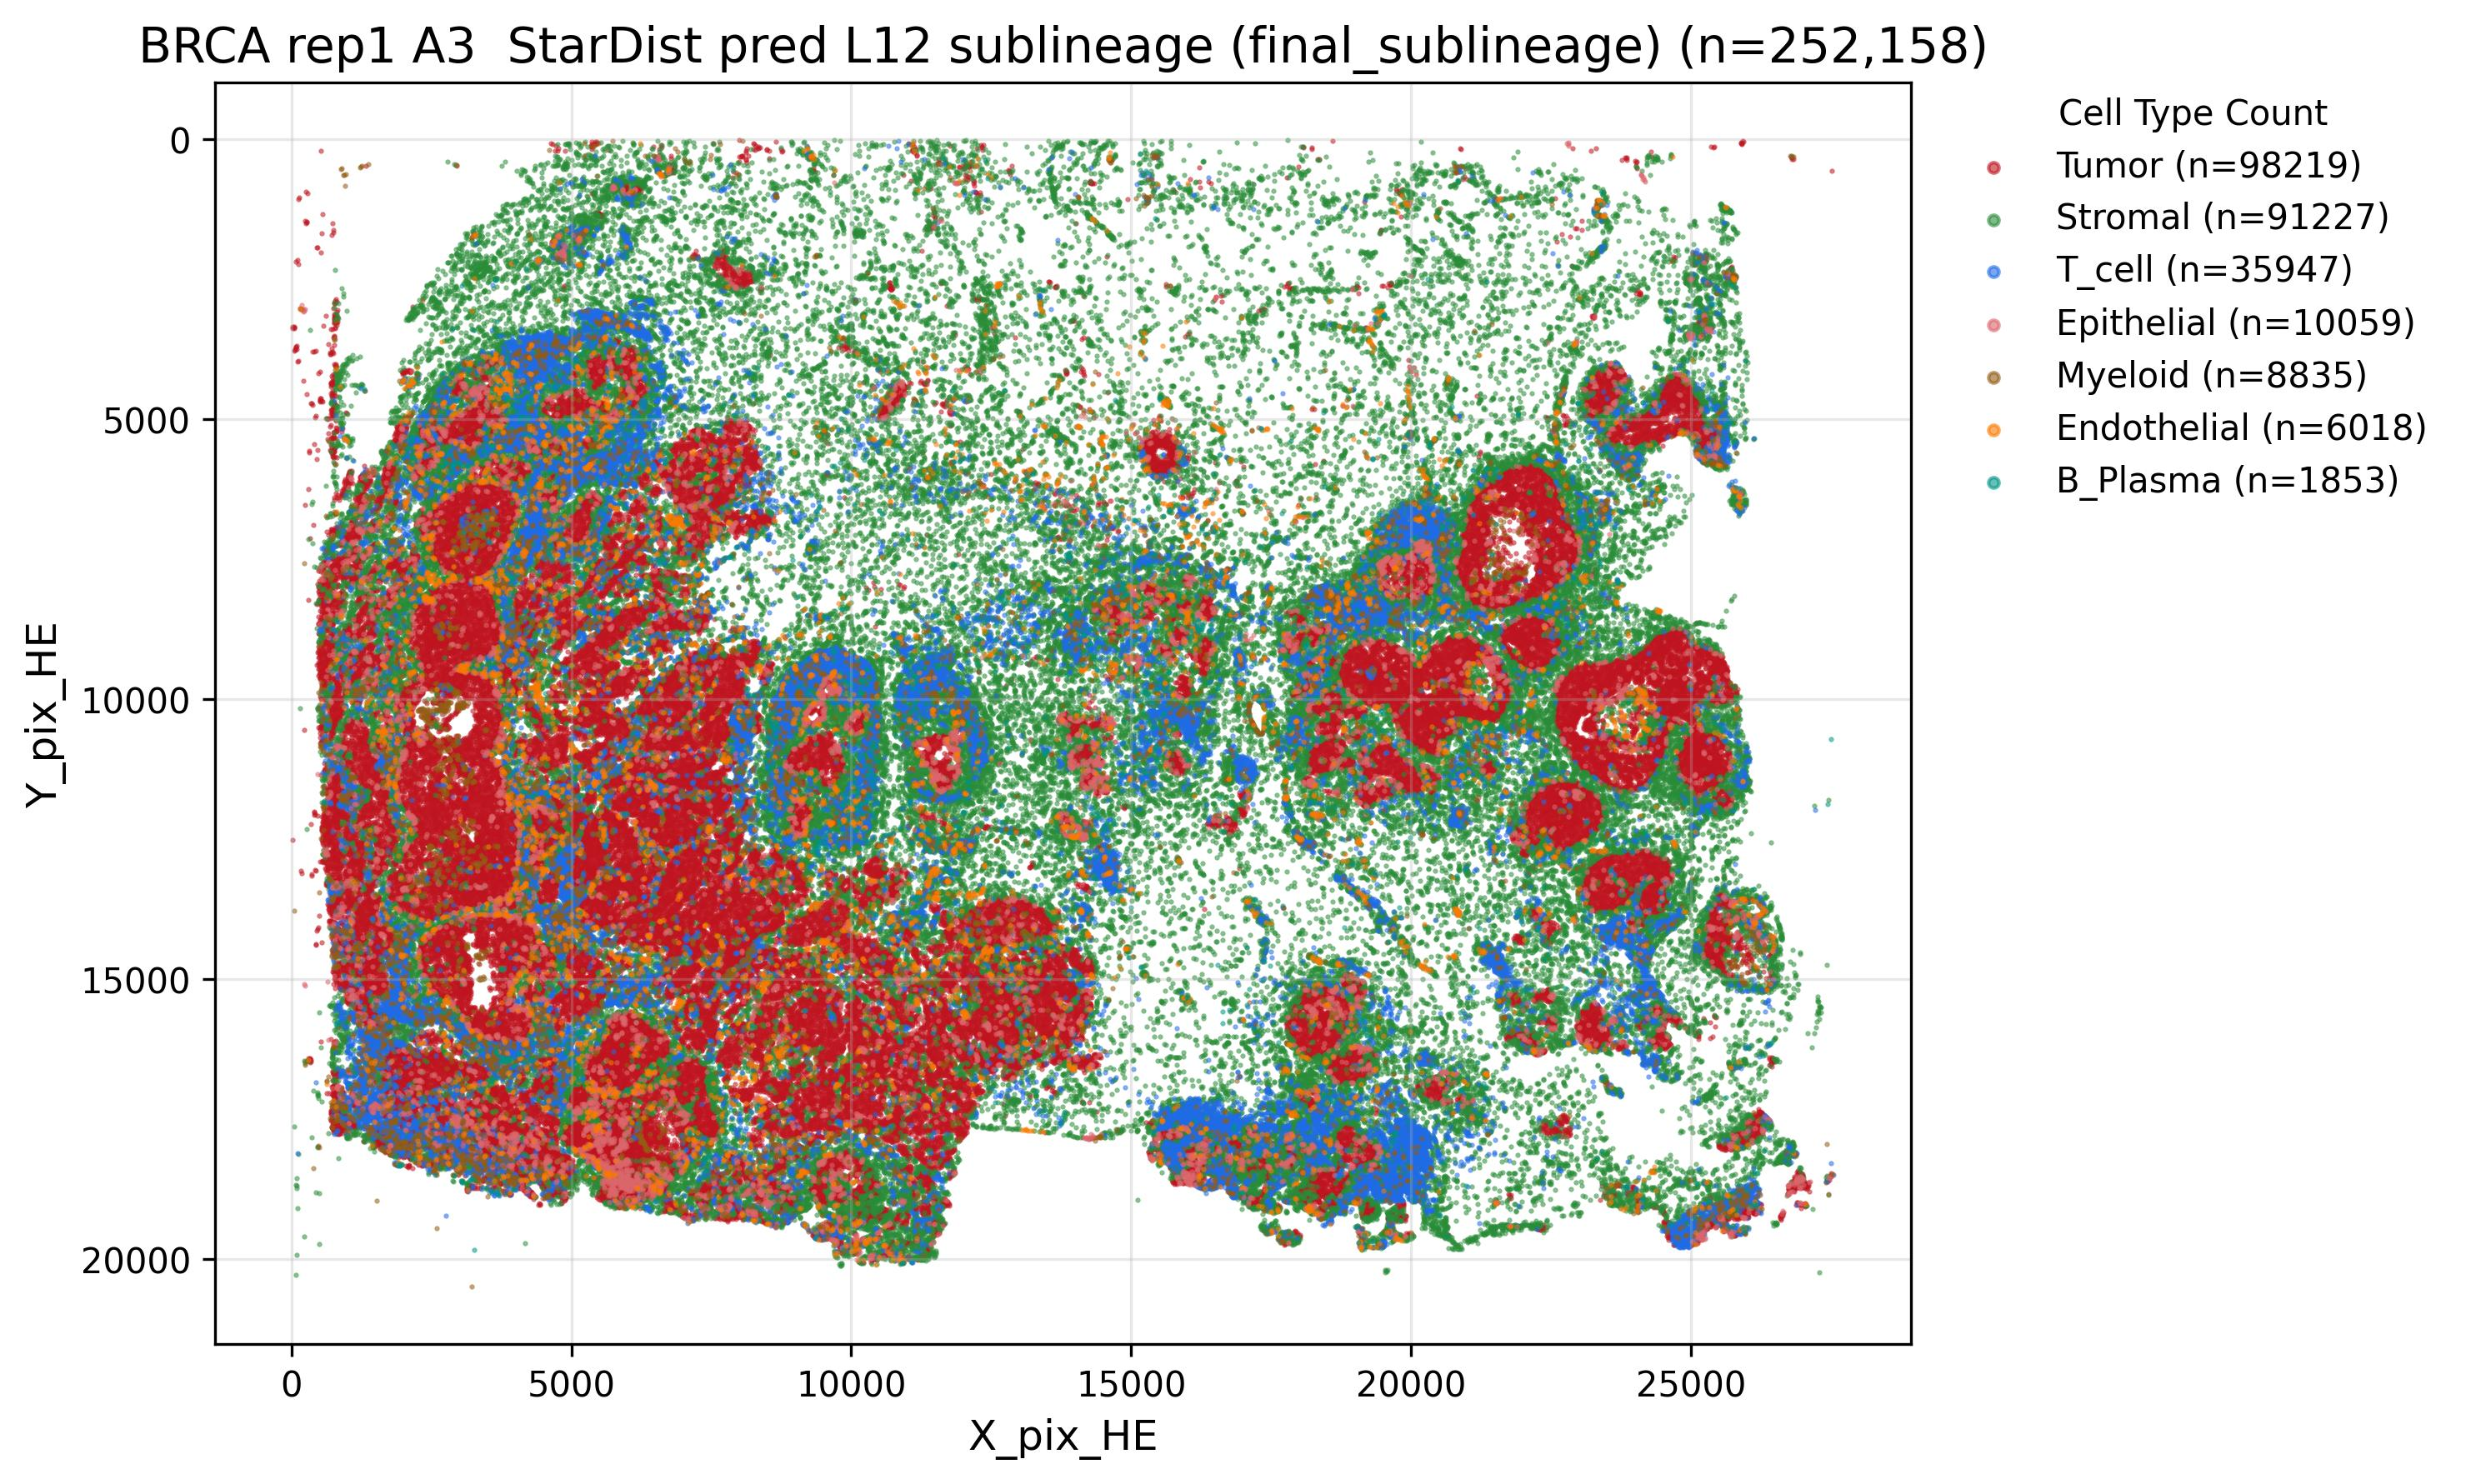

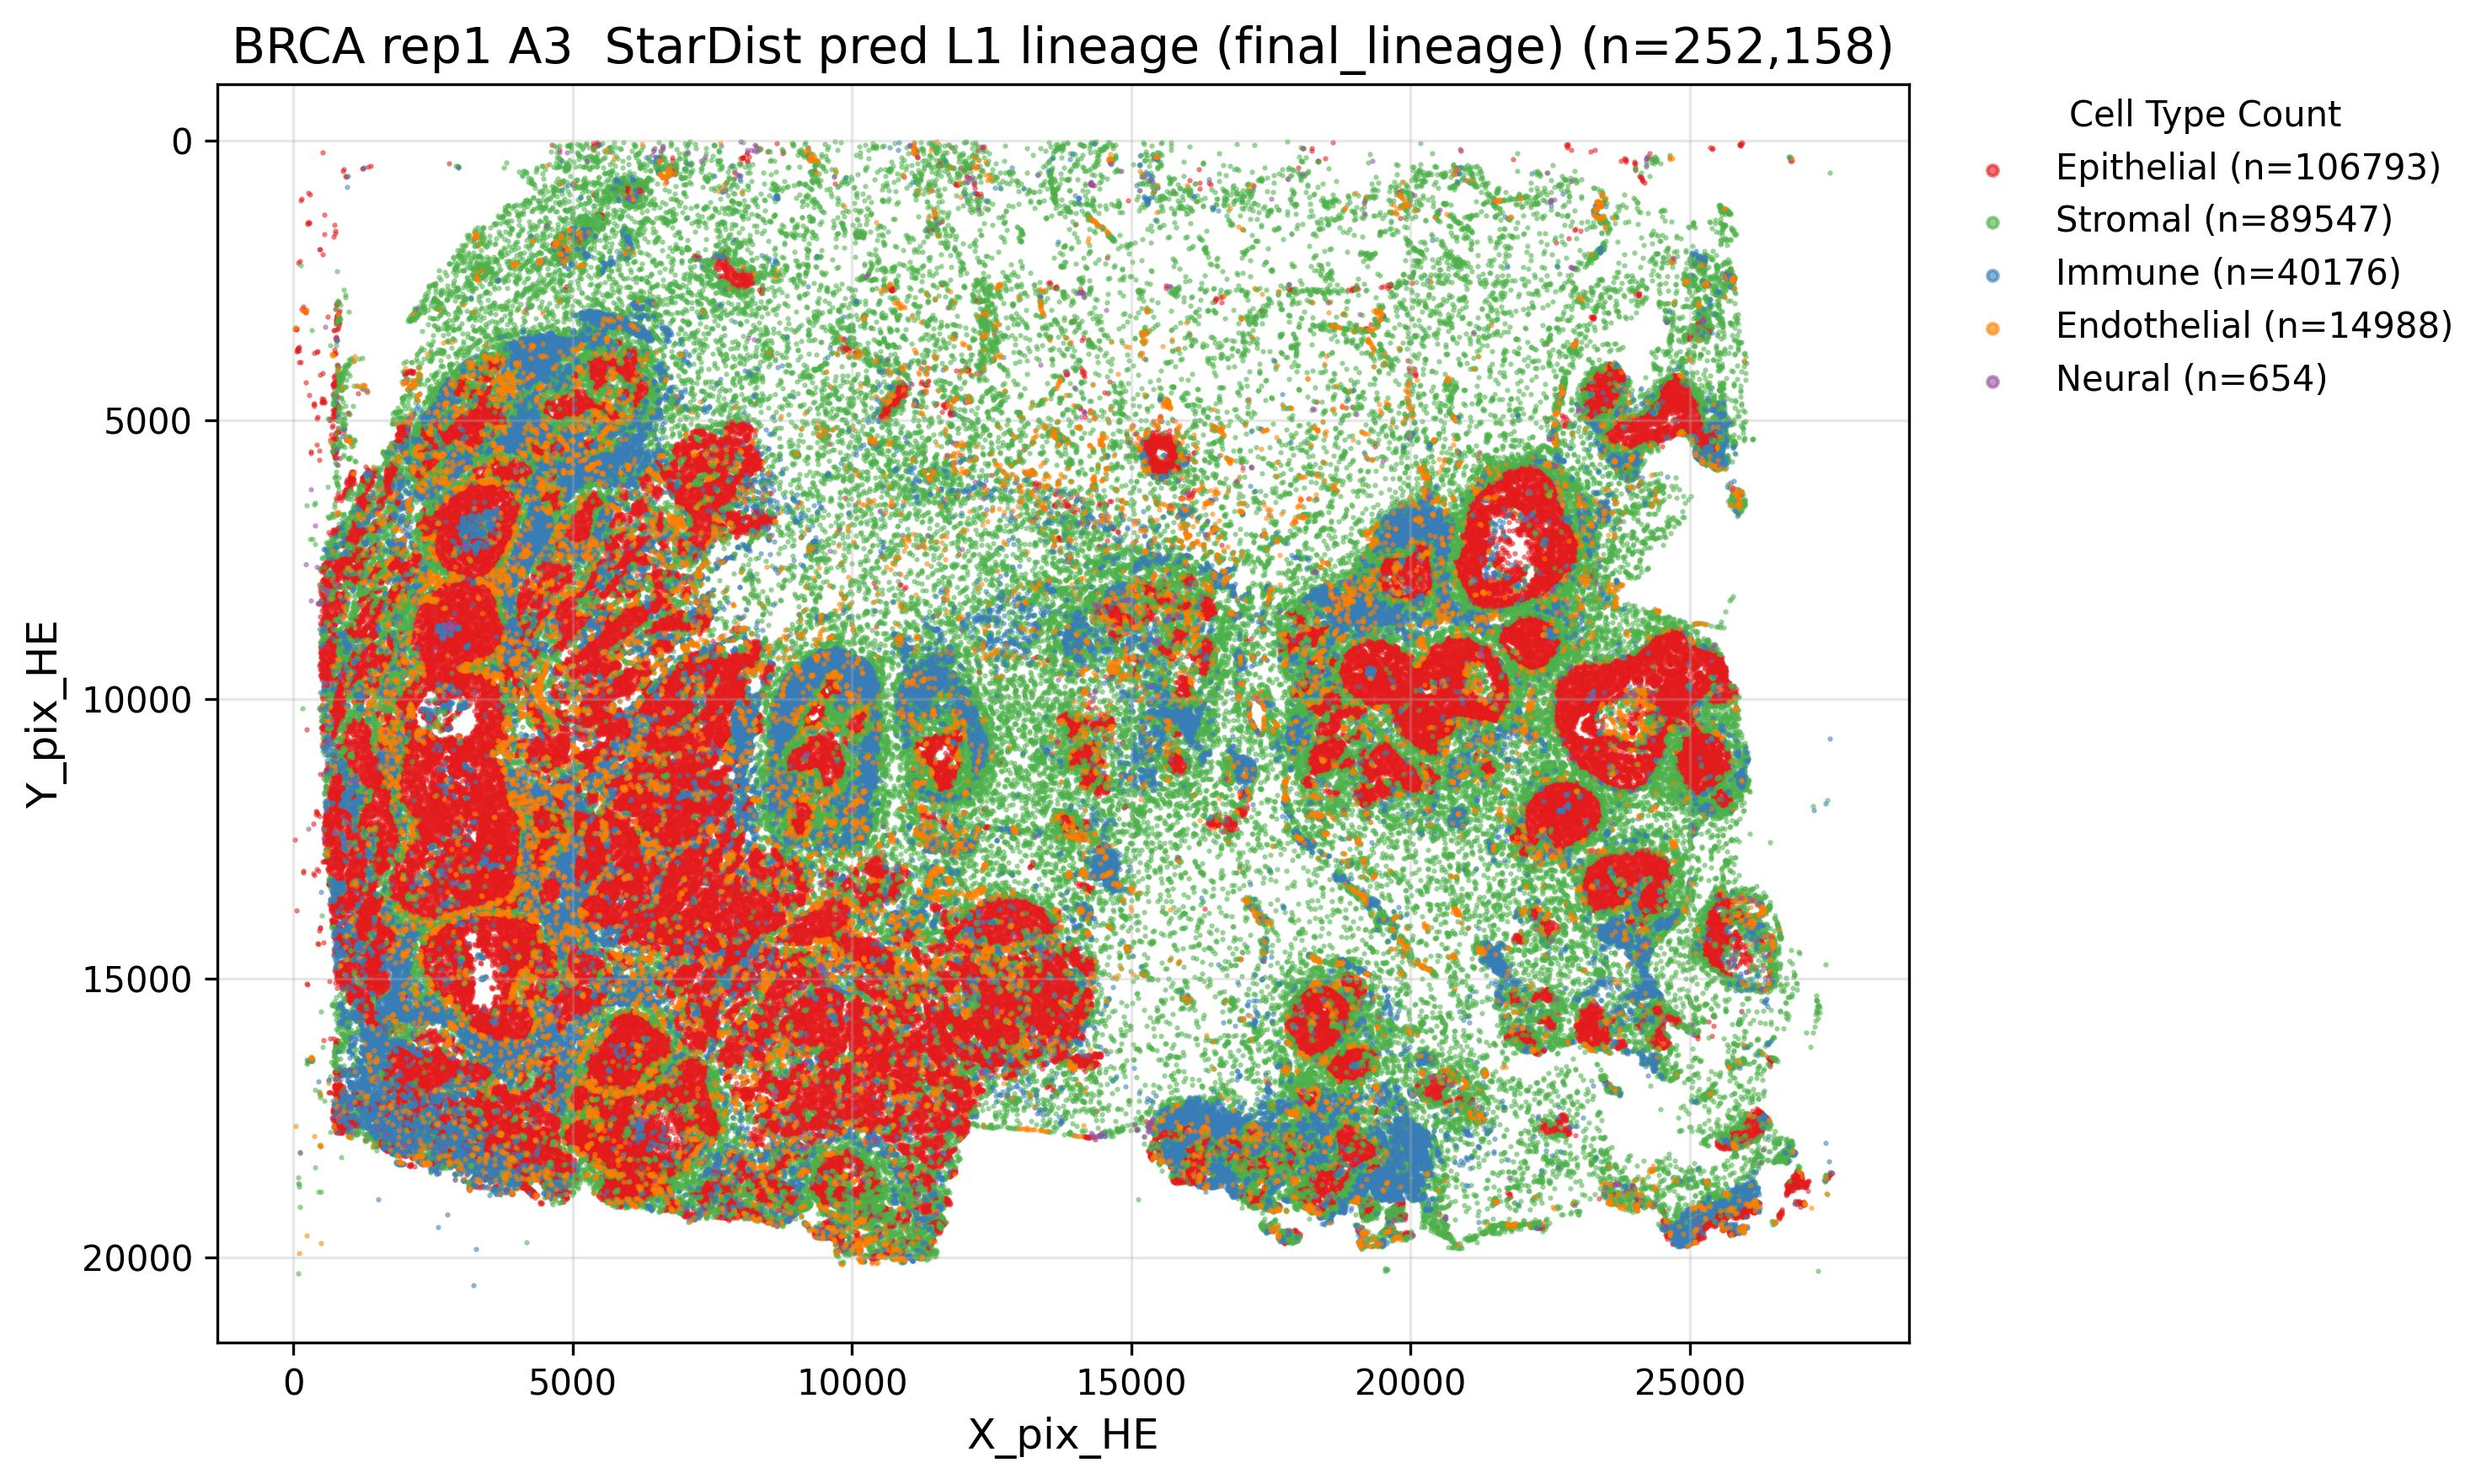

Number of valid data points: 245246
Number of cell types: 18
  Saved predicted spatial plot: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep2/rep2_stardist_pred_l2.jpg
  saved rep2_stardist_pred_l2.jpg
Number of valid data points: 245246
Number of cell types: 7
  Saved predicted spatial plot: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep2/rep2_stardist_pred_l12.jpg
  saved rep2_stardist_pred_l12.jpg
Number of valid data points: 245246
Number of cell types: 5
  Saved predicted spatial plot: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/rep2/rep2_stardist_pred_l1.jpg
  saved rep2_stardist_pred_l1.jpg


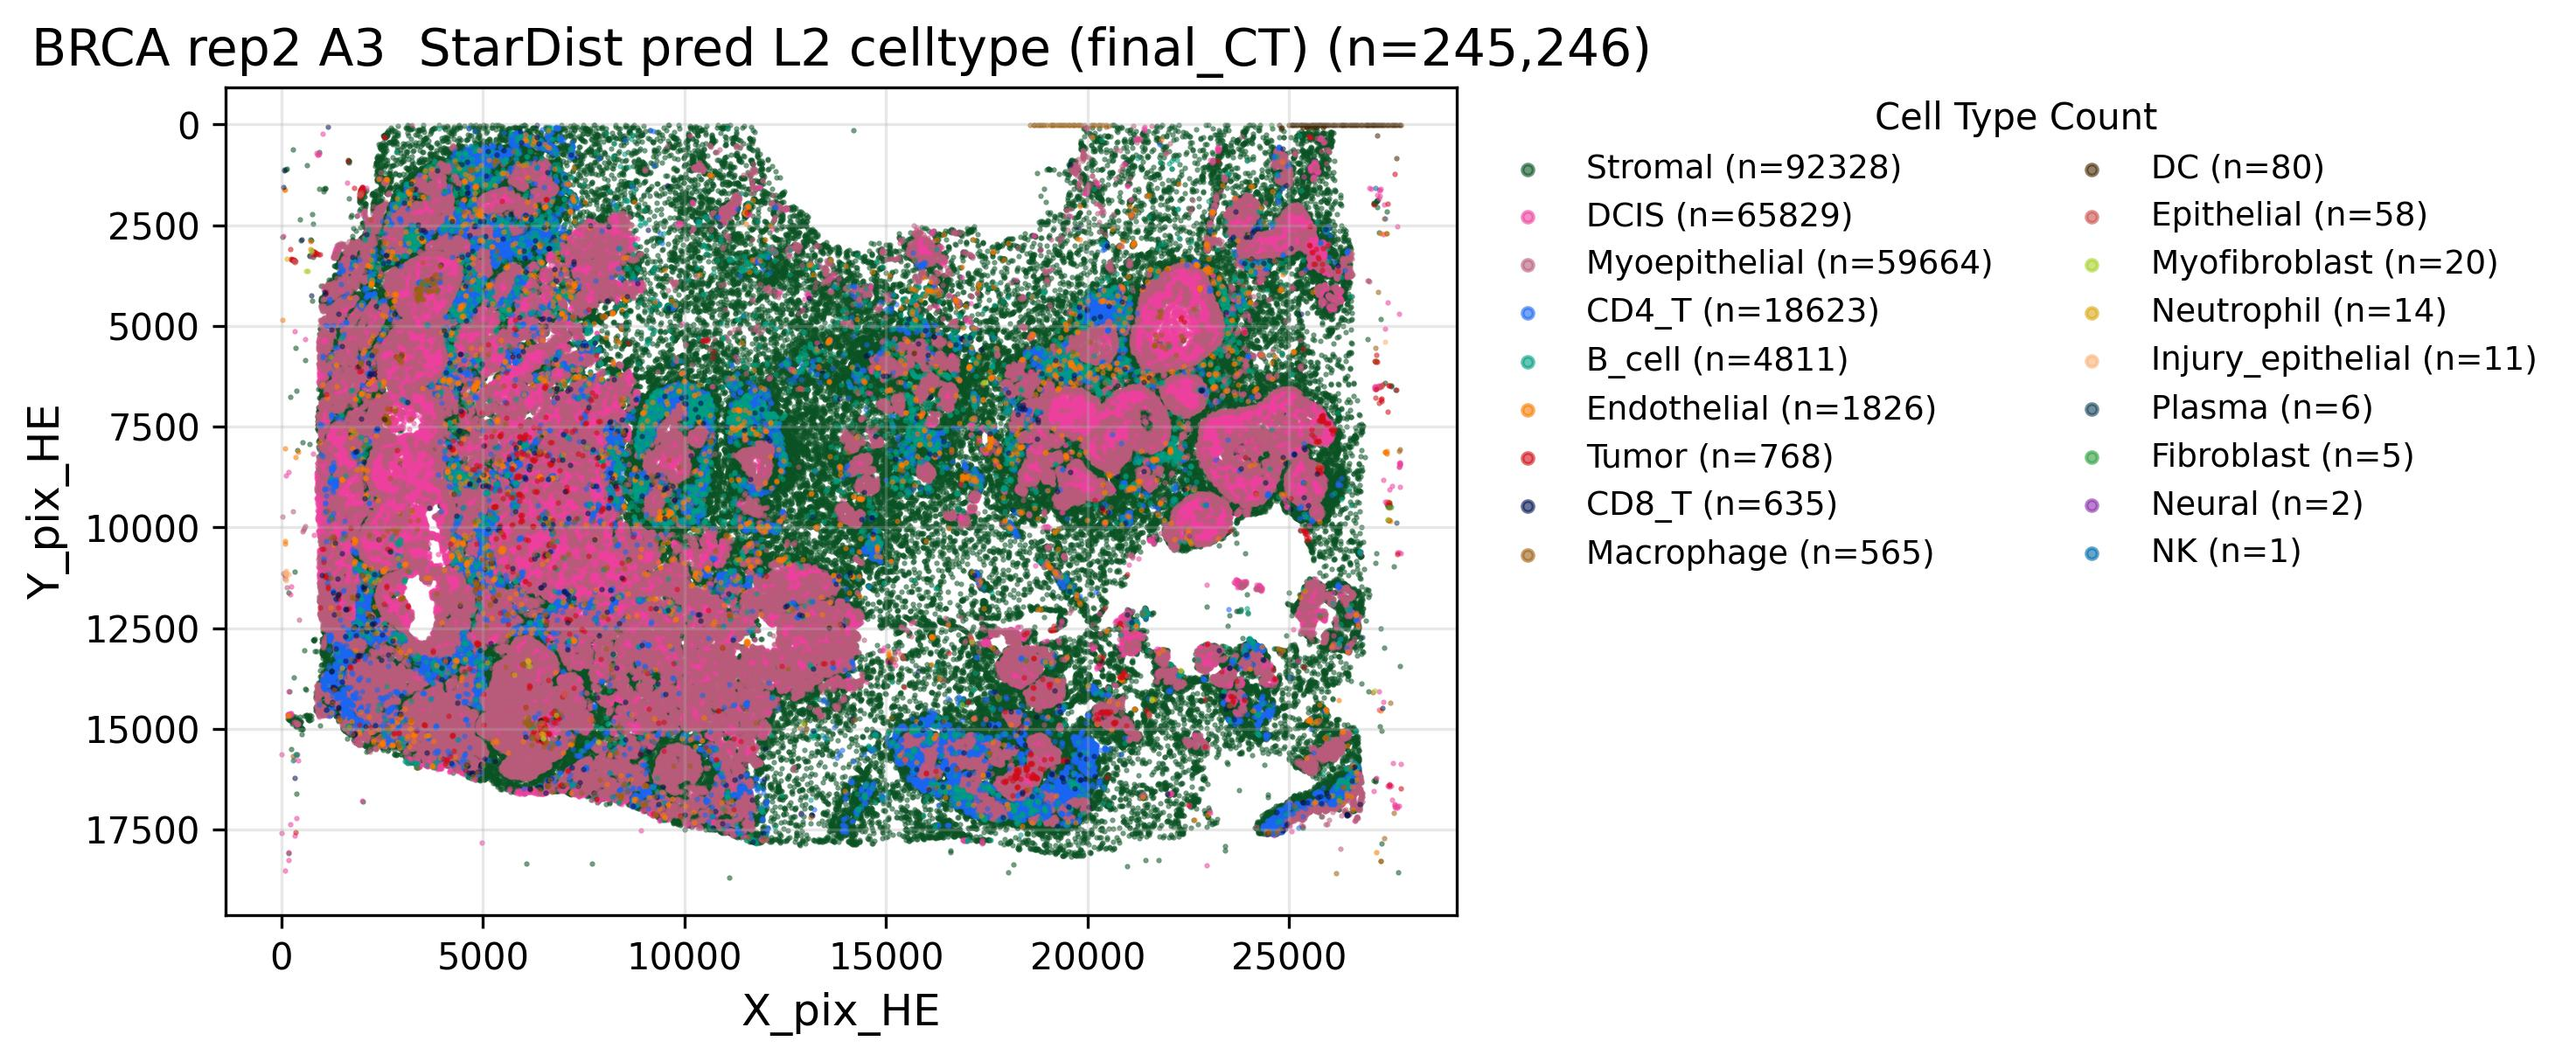

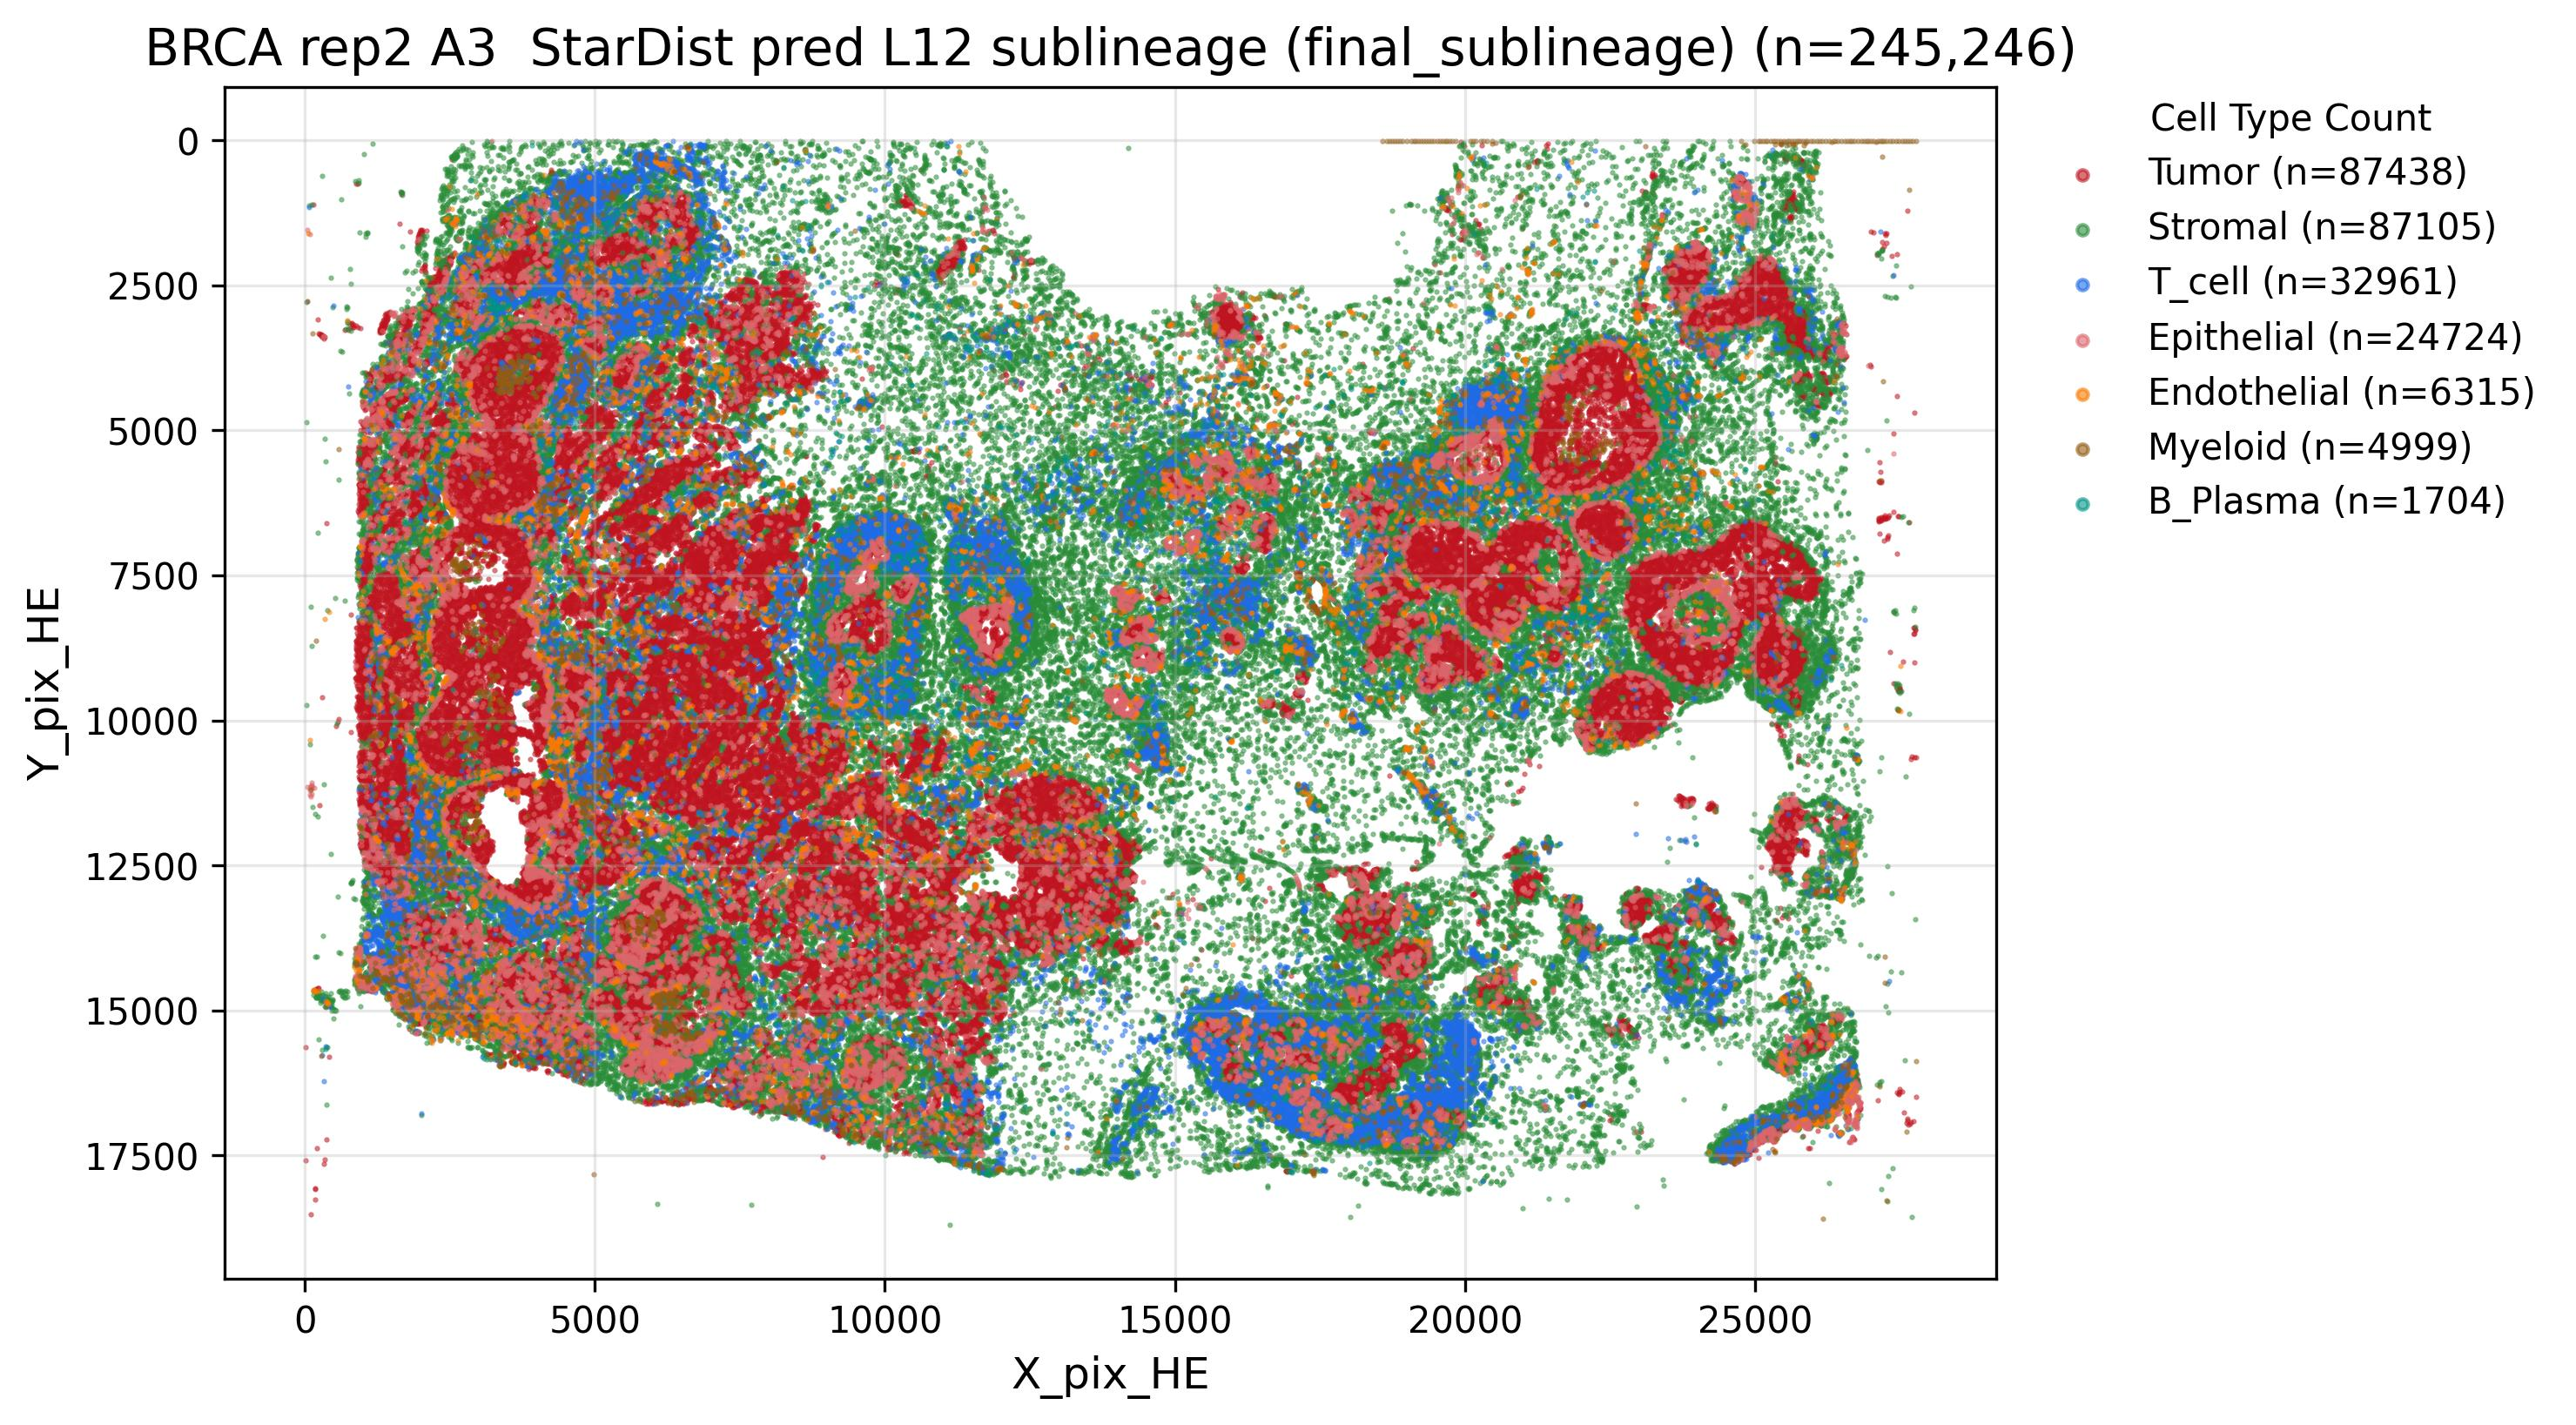

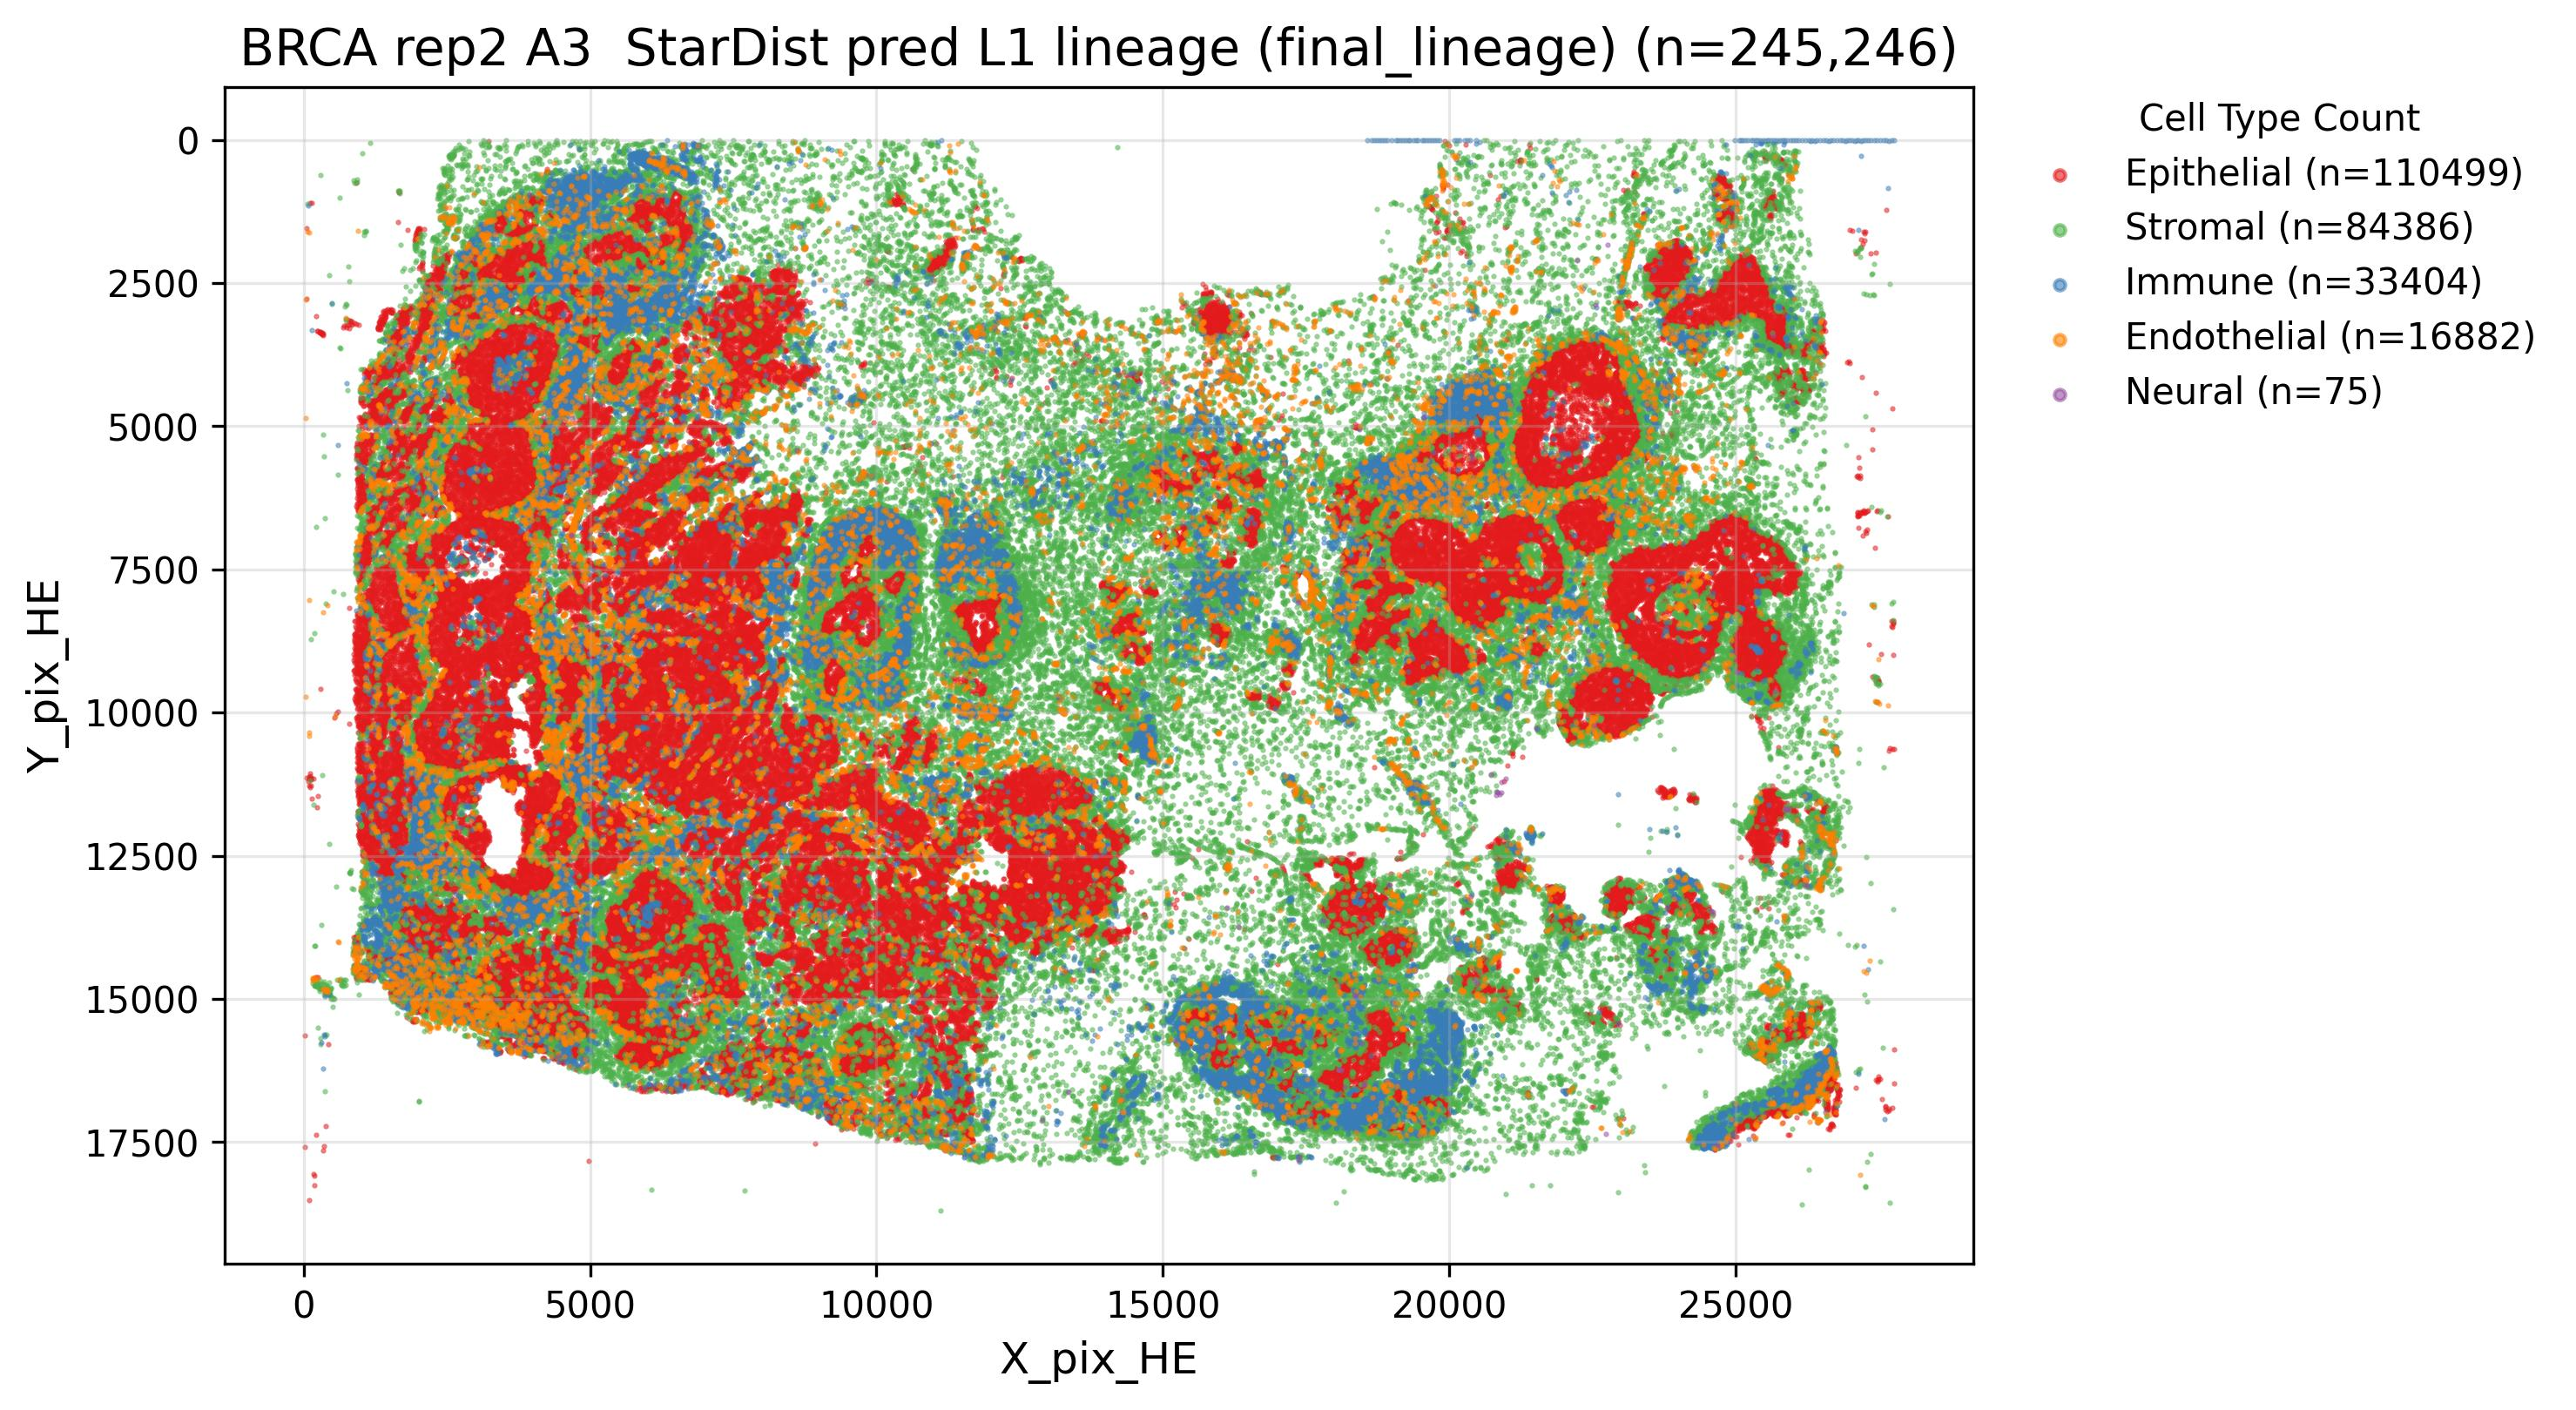

Overview datasets (n=2):
  1. rep1  n=252,158
  2. rep2  n=245,246
  figsize=12.0 × 9.7 in  dpi=200
Overview → /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/stardist_all_pred_overview.jpg


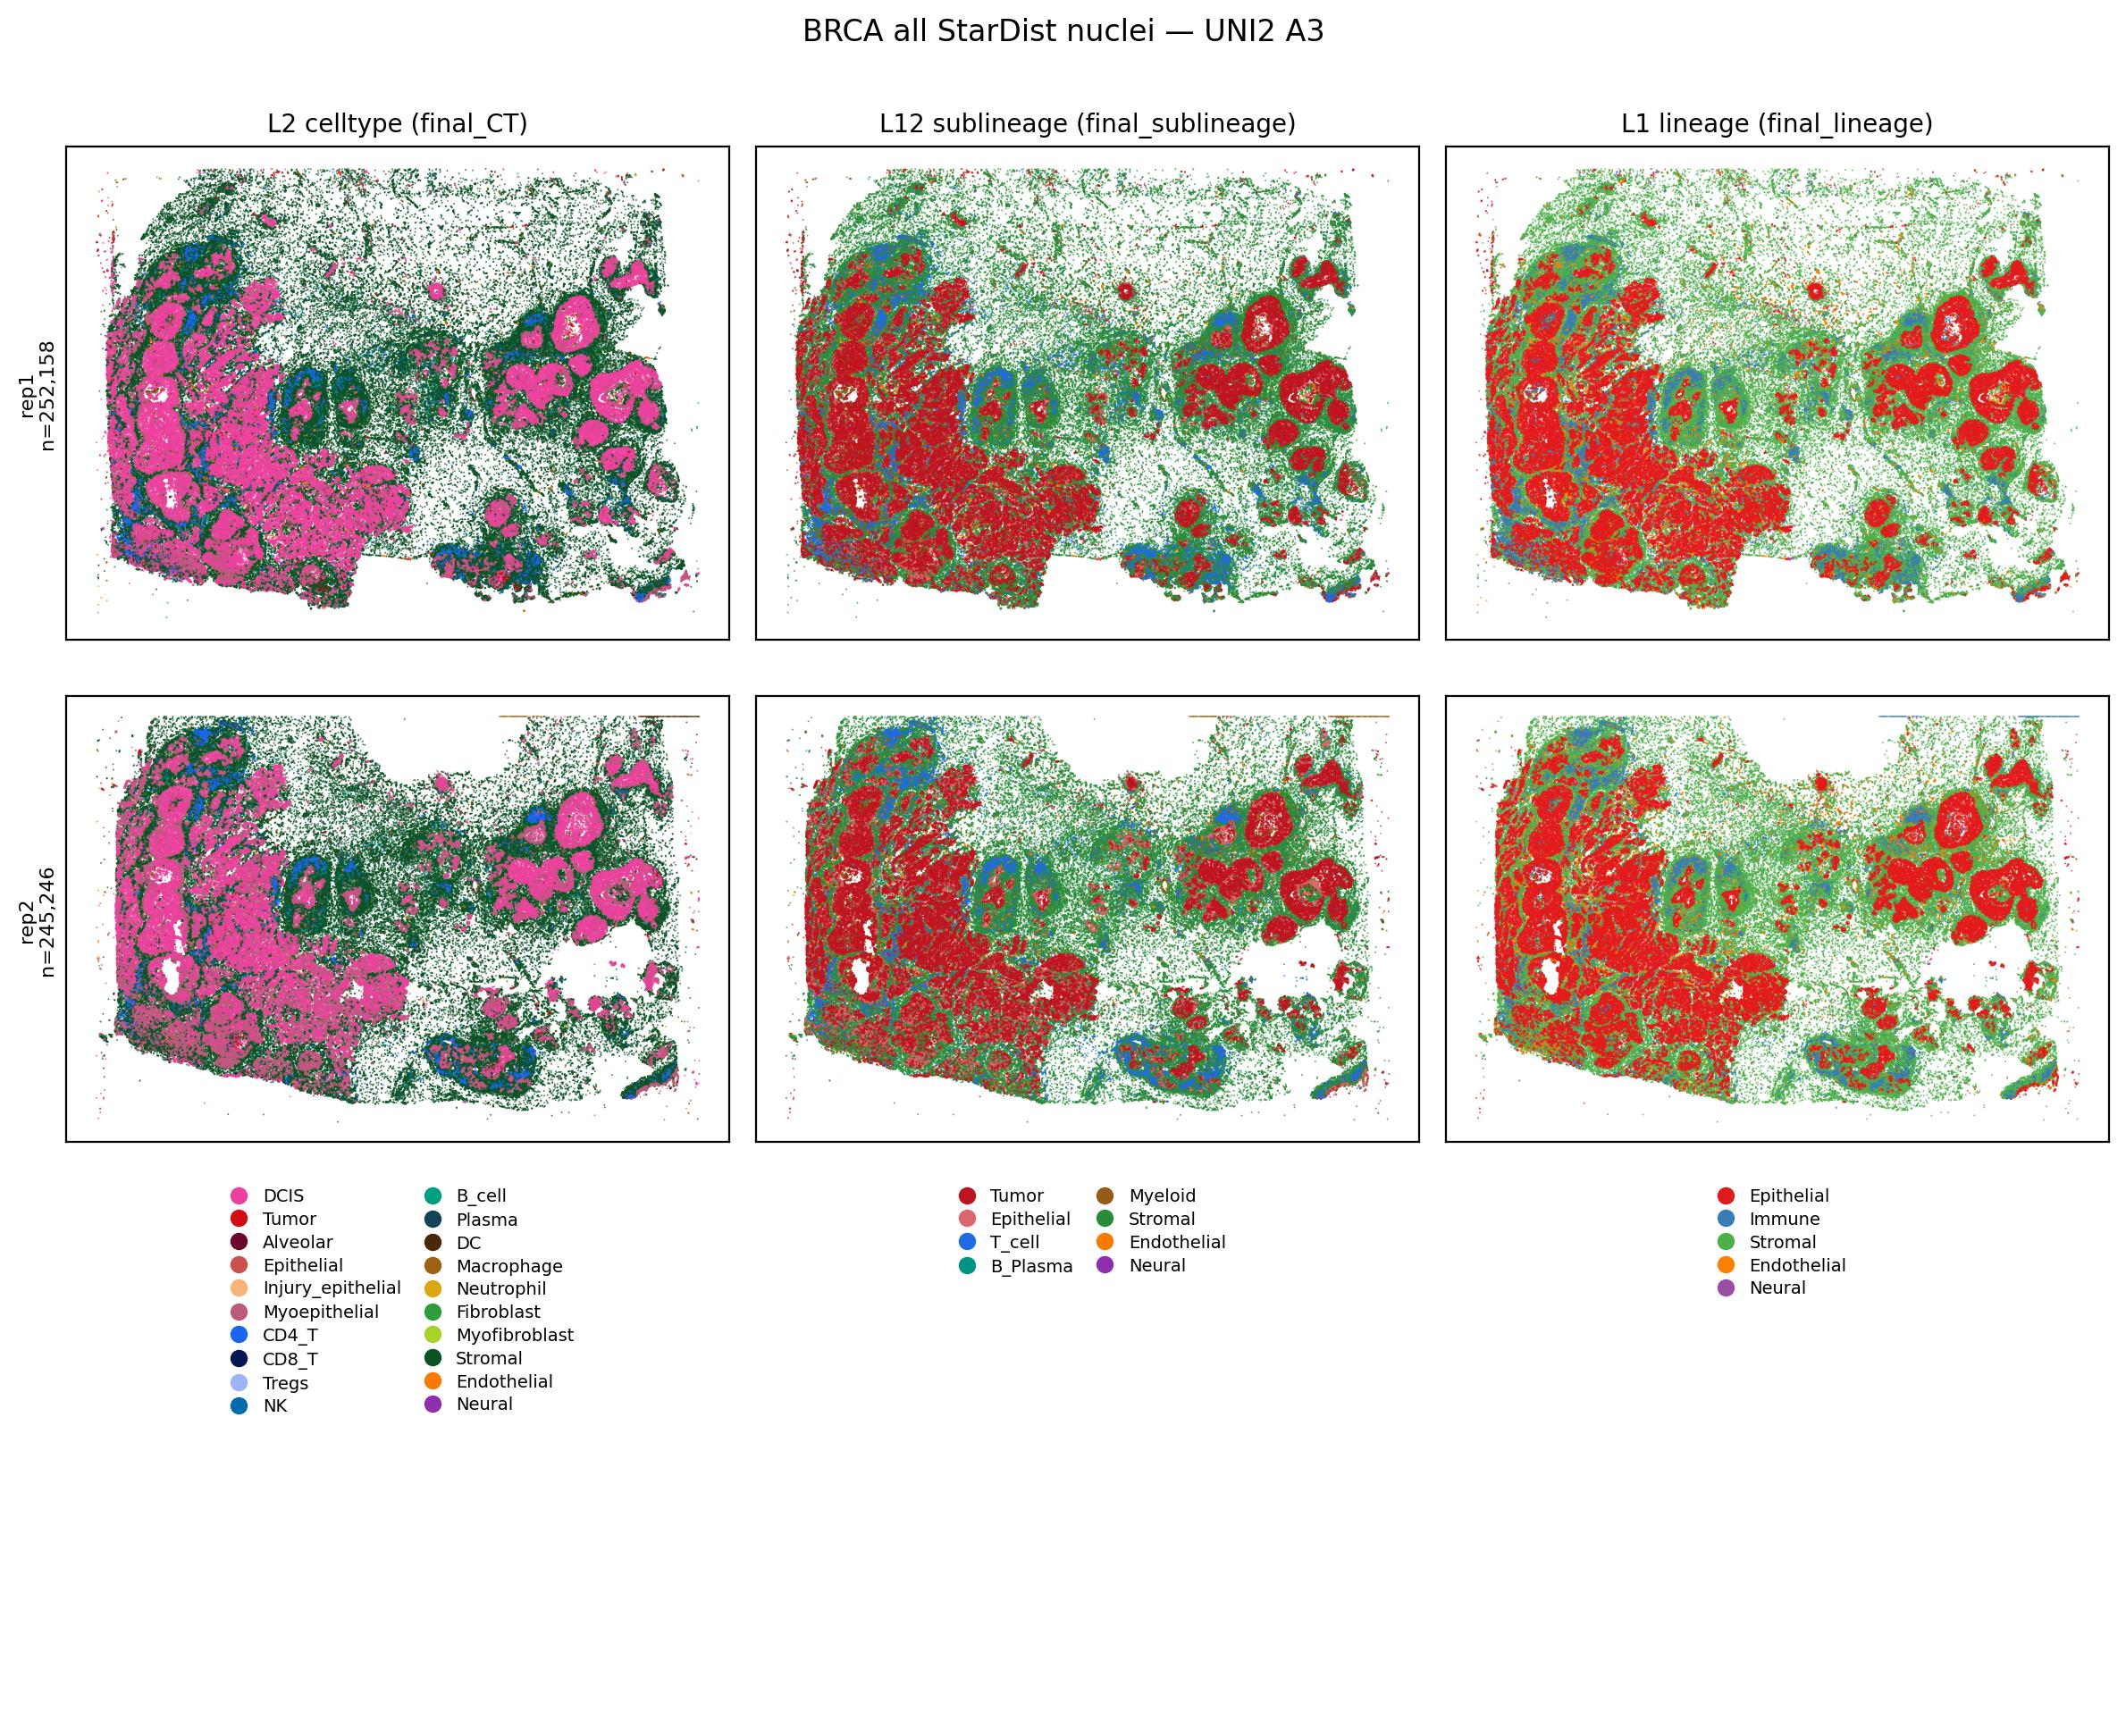

Overview → /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/pred_uni2_A3_bestmlp/stardist_all/BRCA/stardist_all_pred_overview.jpg


In [4]:
import json
import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from uni_label_cv_helpers import (
    plot_stardist_label_spatial_heads,
    plot_stardist_label_spatial_overview,
)

HEADS = ("l2", "l12", "l1")
OBS_COL = {"l2": "pred_CT", "l12": "pred_sublineage", "l1": "pred_lineage"}
CLASS_KEY = {"l2": "L2", "l12": "L12", "l1": "L1"}
classes = json.loads((A3_PRED / "ontology_heads.json").read_text())
loaded = {}
missing = []
for sample in ("rep1", "rep2"):
    token_dir = (
        REPO / "data/Xemium/BRCA/Cases" / sample
        / "project_all_UNI2/ImgEmbeddings_all_stardist/sc_pth_14_14"
    )
    path = A3_PRED / "stardist_all" / "BRCA" / sample / f"{sample}_all_stardist_pred.h5ad"
    if not token_dir.is_dir():
        missing.append(f"{sample}: no UNI2 StarDist tokens at {token_dir}")
        continue
    if not path.is_file():
        missing.append(f"{sample}: tokens exist; re-run the predict cell to write {path.name}")
        continue
    adata = ad.read_h5ad(path)
    coords = np.asarray(adata.obsm["spatial_HE"], dtype=np.float64)[:, :2]
    tiers = {}
    for head in HEADS:
        names = [str(x) for x in classes[CLASS_KEY[head]]]
        index = {name: i for i, name in enumerate(names)}
        pred = np.fromiter(
            (index[str(v)] for v in adata.obs[OBS_COL[head]].astype(str)),
            dtype=np.int64,
            count=adata.n_obs,
        )
        tiers[head] = {"class_names": names, "pred_encoded": pred}
    loaded[sample] = {"path": path, "coords": coords, "n_obs": int(adata.n_obs), "tiers": tiers}
    saved = plot_stardist_label_spatial_heads(
        loaded[sample],
        sample=sample,
        heads=HEADS,
        pan_organ="pancancer",
        show=False,
        title_prefix=f"BRCA {sample} A3",
    )
    for head in HEADS:
        display(Image(filename=str(saved[head])))

if missing:
    print("All-nuclei maps are not ready.")
    for line in missing:
        print(" ", line)
    print("Extract, then re-run the predict cell:")
    print("  SAVE_PATCH_IMAGES=0 bash code/Hist2Pheno_pkg/run_uni2_patch14.sh brca stardist 0")
elif loaded:
    overview = A3_PRED / "stardist_all" / "BRCA" / "stardist_all_pred_overview.jpg"
    fig = plot_stardist_label_spatial_overview(
        loaded,
        heads=HEADS,
        pan_organ="pancancer",
        save_path=overview,
        show=False,
        suptitle="BRCA all StarDist nuclei — UNI2 A3",
    )
    if fig is not None:
        plt.close(fig)
    display(Image(filename=str(overview)))
    print(f"Overview → {overview}")
